In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc')
        tke = flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].mean('time')
        tke_std = (flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].std('time')/np.sqrt(2*12*50)).rename('tke_std')
        print(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc')
        print('lwa')
        lwa = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].mean('time')
        lwa_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].std('time')/np.sqrt(2*365*50)).rename('zonal_flux_std')
        print('F1')
        F1 = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F1'].mean('time')
        F1_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F1'].std('time')/np.sqrt(2*365*50)).rename('F1_std')
        print('F2')
        F2 = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F2'].mean('time')
        F2_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F2'].std('time')/np.sqrt(2*365*50)).rename('F2_std')
        print('F3')
        F3 = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F3'].mean('time')
        F3_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['F3'].std('time')/np.sqrt(2*365*50)).rename('F3_std')
        print('zonal flux')
        zonal_flux = F1+F2+F3
        zonal_flux_std = F1_std + F2_std + F3_std

        tke.name = 'tke'
        lwa.name = 'lwa'
        F1.name = 'F1'
        F2.name = 'F2'
        F3.name = 'F3'
        zonal_flux.name = 'zonal_flux'
        
        tke_std.name = 'tke_std'
        lwa_std.name = 'lwa_std'
        F1_std.name = 'F1_std'
        F2_std.name = 'F2_std'
        F3_std.name = 'F3_std'
        zonal_flux_std.name = 'zonal_flux_std'

        ds = xr.merge([tke,lwa,F1,F2,F3,zonal_flux,tke_std,lwa_std,F1_std,F2_std,F3_std,zonal_flux_std])
        ds.to_netcdf(f'{base_path}/{experiment}/TKE_zonal_flux_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/TKE_zonal_flux_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)

<>:22: SyntaxWarning: invalid escape sequence '\D'
<>:22: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_98743/415979583.py:22: SyntaxWarning: invalid escape sequence '\D'
  """


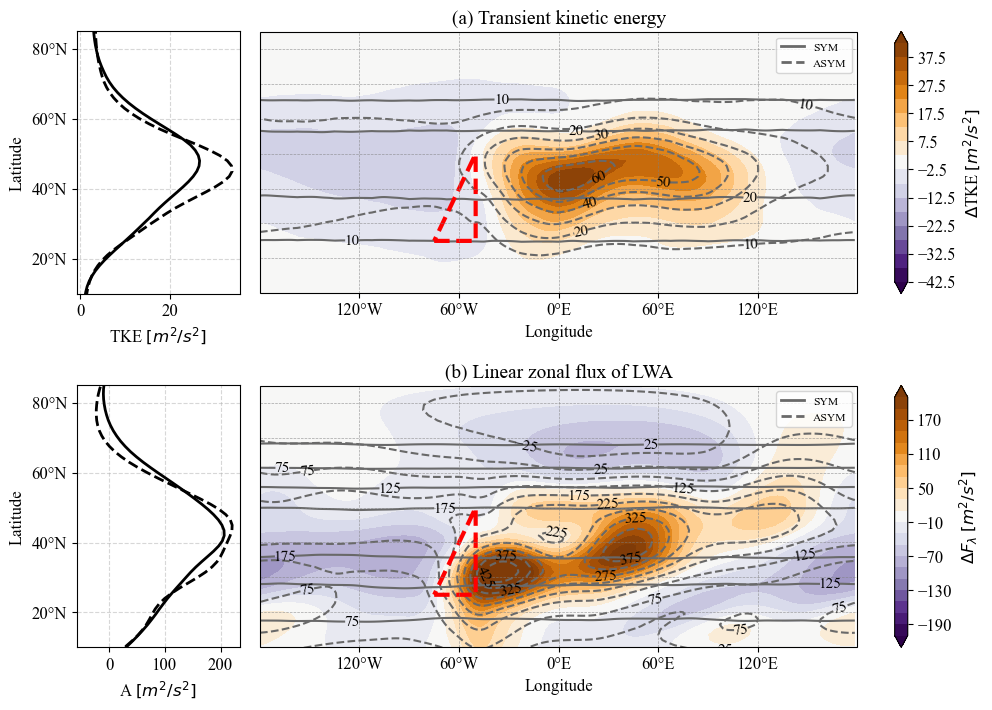

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.lines import Line2D

plt.rcParams['font.size'] = 12

# --------------------------------------------------
# Variable configuration (one entry per row)
# levels / levels_diff: set explicitly, or None to choose automatically
# --------------------------------------------------
variables = [
    dict(var='tke',        title='(a) Transient kinetic energy',
         cbar=r'$\Delta$TKE $[m^2/s^2]$', xlabel=r'TKE $[m^2/s^2]$',
         levels=np.arange(0, 120, 10),  levels_diff=np.arange(-42.5, 43, 5)),
    dict(var='zonal_flux', title='(b) Linear zonal flux of LWA',
         cbar=r'$\Delta F_{\lambda}$ $[m^2/s^2]$', xlabel=r'A $[m^2/s^2]$',
         levels=np.arange(-225, 1300, 50),  levels_diff=np.arange(-210, 220, 20)),
]

"""
    dict(var='F1',  title='(c) F1',
             cbar=r'$\Delta F_1$',  xlabel=r'$F_1$',
             levels=np.linspace(-200, 200, 12),  levels_diff=np.linspace(-150, 150, 20)),
        dict(var='F2',  title='(d) F2',
             cbar=r'$\Delta F_2$',  xlabel=r'$F_2$',
             levels=np.linspace(-200, 200, 12),  levels_diff=np.linspace(-150, 150, 20)),
        dict(var='F3',  title='(e) F3',
             cbar=r'$\Delta F_3$',  xlabel=r'$F_3$',
             levels=np.linspace(-200, 200, 12),  levels_diff=np.linspace(-150, 150, 20)),
        dict(var='lwa', title='(f) LWA',
             cbar=r'$\Delta$LWA',   xlabel=r'LWA',
             levels=np.arange(3,25,2),  levels_diff=np.arange(-10.5, 10.6, 1)),
"""

def auto_levels(da0, da1, n=10, diff=False):
    """Fallback levels, used only when none are given explicitly."""
    if diff:
        vmax = np.nanpercentile(np.abs((da1 - da0).values), 99)
        return np.linspace(-vmax, vmax, 21)
    both = np.concatenate([da0.values.ravel(), da1.values.ravel()])
    return np.linspace(np.nanpercentile(both, 1), np.nanpercentile(both, 99), n)

# --------------------------------------------------
# Figure + GridSpec
# --------------------------------------------------
nrows = len(variables)
fig = plt.figure(figsize=(12, 4 * nrows))

gs = gridspec.GridSpec(
    nrows=nrows, ncols=3,
    width_ratios=[1.2, 0.15, 5.5],
    hspace=0.35, wspace=0.0
)

# Triangle coordinates
coords = [(-75, 25), (-50, 25), (-50, 50)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

custom_lines = [
    Line2D([0], [0], color='dimgray', lw=2, linestyle='solid',  label='SYM'),
    Line2D([0], [0], color='dimgray', lw=2, linestyle='dashed', label='ASYM')
]

lonmin = float(ds_clims[0].lon.min())
lonmax = float(ds_clims[0].lon.max())

xticks = [-120, -60, 0, 60, 120]
xtick_labels = ['120°W', '60°W', '0°E', '60°E', '120°E']

# --------------------------------------------------
# Loop over rows
# --------------------------------------------------
for i, v in enumerate(variables):
    name = v['var']
    da0, da1 = ds_clims[0][name], ds_clims[2][name]

    levels      = v['levels']      if v['levels']      is not None else auto_levels(da0, da1)
    levels_diff = v['levels_diff'] if v['levels_diff'] is not None else auto_levels(da0, da1, diff=True)

    ax_xsec = fig.add_subplot(gs[i, 0])
    ax_map  = fig.add_subplot(gs[i, 2], projection=ccrs.PlateCarree(), sharey=ax_xsec)

    # ---- Map ----
    ax_map.set_title(v['title'])

    # linestyles='solid' for SYM so negative contours (e.g. fluxes) aren't drawn dashed
    c1 = ax_map.contour(da0.lon, da0.lat, da0, levels=levels,
                        colors='dimgray', linestyles='solid')
    c2 = ax_map.contour(da1.lon, da1.lat, da1, levels=levels,
                        colors='dimgray', linestyles='dashed')

    ax_map.clabel(c1, inline=True, colors='black', inline_spacing=1, rightside_up=True, fontsize=11)
    ax_map.clabel(c2, inline=True, colors='black', inline_spacing=1, rightside_up=True, fontsize=11)

    sh = ax_map.contourf(da0.lon, da0.lat, da1 - da0,
                         levels=levels_diff, cmap='PuOr_r', extend='both')
    fig.colorbar(sh, ax=ax_map, label=v['cbar'])

    ax_map.plot(lons, lats, '--', lw=3, color='red', transform=ccrs.PlateCarree())

    ax_map.set_extent([lonmin, lonmax, 10, 85])
    ax_map.set_aspect(2.1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_xticklabels(xtick_labels)
    ax_map.set_xlabel('Longitude')

    ax_map.legend(handles=custom_lines, loc='upper right', fontsize='x-small')
    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

    # ---- Cross-section ----
    ax_xsec.plot(da1.mean('lon'), ds_clims[0].lat, color='k', linestyle='dashed', lw=2)
    ax_xsec.plot(da0.mean('lon'), ds_clims[0].lat, color='k', linestyle='solid',  lw=2)
    ax_xsec.set_xlabel(v['xlabel'])
    ax_xsec.set_ylabel('Latitude')
    ax_xsec.grid(True, ls='--', alpha=0.5)
    ax_xsec.set_yticks([20, 40, 60, 80])
    ax_xsec.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])

    plt.setp(ax_map.get_yticklabels(), visible=False)

plt.savefig('PLOTS/Figure2_with_xsec.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
import numpy as np
import xarray as xr

def zonal_derivative(field, lon_name='lon', lat_name='lat', radius=6371000):
    """
    Compute the zonal (longitude) derivative of a field on a sphere.
    
    Parameters:
        field (xr.DataArray): Input field with 'lon' and 'lat' coordinates.
        lon_name (str): Name of the longitude coordinate.
        lat_name (str): Name of the latitude coordinate.
        radius (float): Radius of the sphere (default: Earth's radius in meters).
        
    Returns:
        xr.DataArray: Zonal derivative of the field.
    """
    # Get longitude and latitude arrays in radians
    lon = np.deg2rad(field[lon_name].values)
    lat = np.deg2rad(field[lat_name].values)

    # Compute delta_lon (assume regular grid)
    dlon = np.gradient(lon)  # shape: (nlon,)
    print(dlon)

    # Compute cos(lat) for each latitude
    coslat = np.cos(lat)  # shape: (nlat,)

    # Compute dx for each (lat, lon) point
    # dx = R * cos(lat) * dlon
    # We want dx to be shape (nlat, nlon)
    dx = radius * np.outer(coslat, dlon)  # shape: (nlat, nlon)

    # Compute finite difference along longitude axis
    # Use xarray's .differentiate for correct coordinate handling
    dfield_dlon = field.differentiate(coord=lon_name, edge_order=2)

    # Now divide by dx (broadcasting over lat/lon)
    zonal_deriv = dfield_dlon / dx

    # Assign correct attributes and return
    zonal_deriv.attrs = field.attrs
    return zonal_deriv


In [7]:
import numpy as np

def zonal_convergence(F_lambda, lon_name="lon", lat_name="lat"):
    """
    Zonal component of LWA flux convergence: -(1/(a cosφ)) dF/dλ
    """
    a = 6.371e6  # Earth radius, m

    lat_rad = np.deg2rad(F_lambda[lat_name])

    # dF/d(lon in degrees) -> dF/d(lon in radians): multiply by 180/pi
    dF_dlambda = F_lambda.differentiate(lon_name) * (180 / np.pi)

    conv = -dF_dlambda / (a * np.cos(lat_rad))
    return conv